# Dated works and floruits
How many individuals can be placed in time by their works or by a floruit, and in which centuries.

In [1]:
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.append('../notebooks')
from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

FIRST_CENTURY = -1000
LAST_CENTURY = 2000
PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)

SERIES_COLORS = {
    'At least 2 precise works': BLUE,
    'Only 1 precise work': LIGHT_BLUE,
    '"fl." in description': ORANGE,
    'Only 1 precise floruit': GREEN,
    'Only 1 precise floruit, no birth or death': LIGHT_GREEN,
    'Any of these dates': NAVY,
    'Birth date, year or decade': PURPLE,
    'Birth date, century or coarser': LIGHT_PURPLE,
}

apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)

## Load the data
A work's date is its publication date, else its inception, as for `works_period`. A decade-precise date is moved to the middle of its decade. Each individual gets one row: dated works, precise dated works, earliest precise work year.

In [2]:
works = connection.execute('''
    WITH dated AS (
        SELECT individual_work.qid,
               individual_work.work_qid,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE coalesce(work.publication_date.year, work.inception.year) IS NOT NULL
    )
    SELECT qid,
           count(DISTINCT work_qid) AS dated_works,
           count(DISTINCT work_qid) FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS precise_works,
           min(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END)
               FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS first_precise_year
    FROM dated
    GROUP BY qid
''').pl()
print(f'{len(works):,} individuals with at least one dated work')
works.sample(5, seed=0)

2,780,765 individuals with at least one dated work


qid,dated_works,precise_works,first_precise_year
str,i64,i64,i64
"""Q88471097""",1,1,1891
"""Q47504309""",4,4,2016
"""Q85619529""",3,3,2015
"""Q115774086""",1,1,2023
"""Q90917573""",3,3,2016


In [3]:
floruit = connection.execute('''
    SELECT entity.qid AS qid,
           entity.description AS description,
           list_distinct([CASE WHEN date.precision = 'decade' THEN date.year + 5 ELSE date.year END
                          FOR date IN floruit_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS precise_years,
           len(birth_date) > 0 OR len(death_date) > 0 AS has_birth_or_death
    FROM individual
    WHERE len(floruit_date) > 0 OR regexp_matches(entity.description, '\\bfl\\.')
''').pl()
print(f'{len(floruit):,} individuals with a floruit property or "fl." in their description')
floruit.sample(5, seed=0)

74,337 individuals with a floruit property or "fl." in their description


qid,description,precise_years,has_birth_or_death
str,str,list[i64],bool
"""Q12305362""","""Danish painter (1841-1893)""",[1874],true
"""Q126961641""",null,[1990],false
"""Q125521114""",null,[1898],false
"""Q104243633""","""ancient Greek astronomer""",[],false
"""Q135241319""",null,[1930],false


In [4]:
def by_century(frame, year_column):
    in_range = frame.with_columns((pl.col(year_column) // 100 * 100).alias('century_start')).filter(
        pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY))
    print(f'{frame.height - in_range.height:,} individuals outside {FIRST_CENTURY}–{LAST_CENTURY + 99} or without a year left out of the table')
    return in_range.group_by('century_start').len('individuals').sort('century_start')


def plot_centuries(series, labelled=()):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for name, frame in series.items():
        frame = frame.filter(pl.col('individuals') > 0)
        ax.plot(frame['century_start'], frame['individuals'], marker='o', markersize=5, color=SERIES_COLORS[name], label=name)
        if name in labelled:
            for x, y in zip(frame['century_start'], frame['individuals']):
                ax.annotate(f'{y:,}', (x, y), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=POINT_LABEL_FONTSIZE, color=TEXT)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xlim(FIRST_CENTURY - 50, LAST_CENTURY + 50)
    ax.set_xlabel('Century (start year)')
    ax.grid(axis='y')
    ax.legend(loc='upper left')
    plt.show()

## 1. Individuals with at least two dated works

In [5]:
two_dated = works.filter(pl.col('dated_works') >= 2)
two_precise = works.filter(pl.col('precise_works') >= 2)
print(f'{two_dated.height:,} individuals with at least 2 dated works (any precision)')
print(f'{two_precise.height:,} of them with at least 2 works dated to the year or decade')
assert two_precise.height <= two_dated.height

1,794,294 individuals with at least 2 dated works (any precision)
1,789,214 of them with at least 2 works dated to the year or decade


### By century of their first precise work

In [6]:
two_precise_century = by_century(two_precise, 'first_precise_year')
two_precise_century

7 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-800,2
-700,2
-600,14
-500,35
-400,23
-300,7
-200,3
-100,14


### Figure: individuals with at least 2 precise works, by century

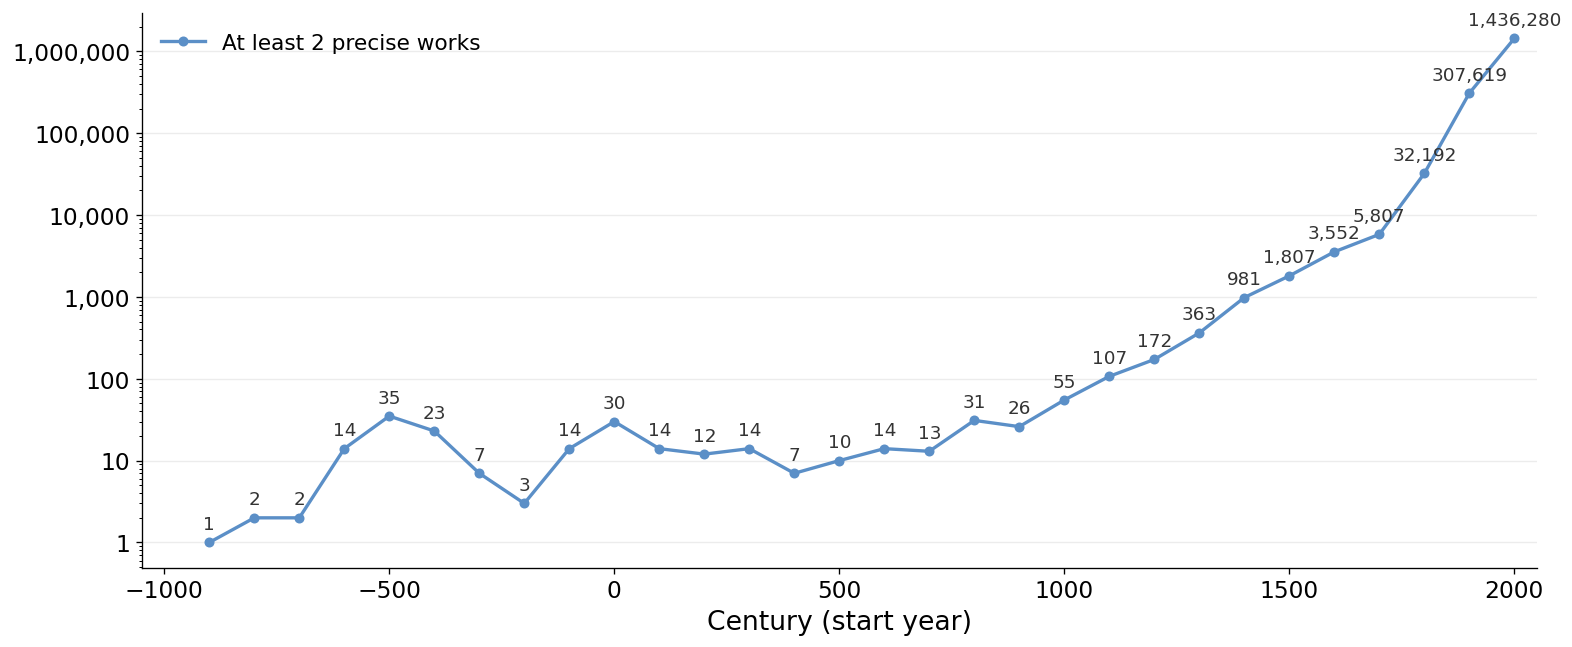

In [7]:
plot_centuries({'At least 2 precise works': two_precise_century}, labelled=['At least 2 precise works'])

### One example per century
The individual with the most Wikimedia pages among those whose first precise work falls in the century, with their two earliest precise works that have a title. Long titles are cut at 50 characters.

30 centuries, 30 in the chart


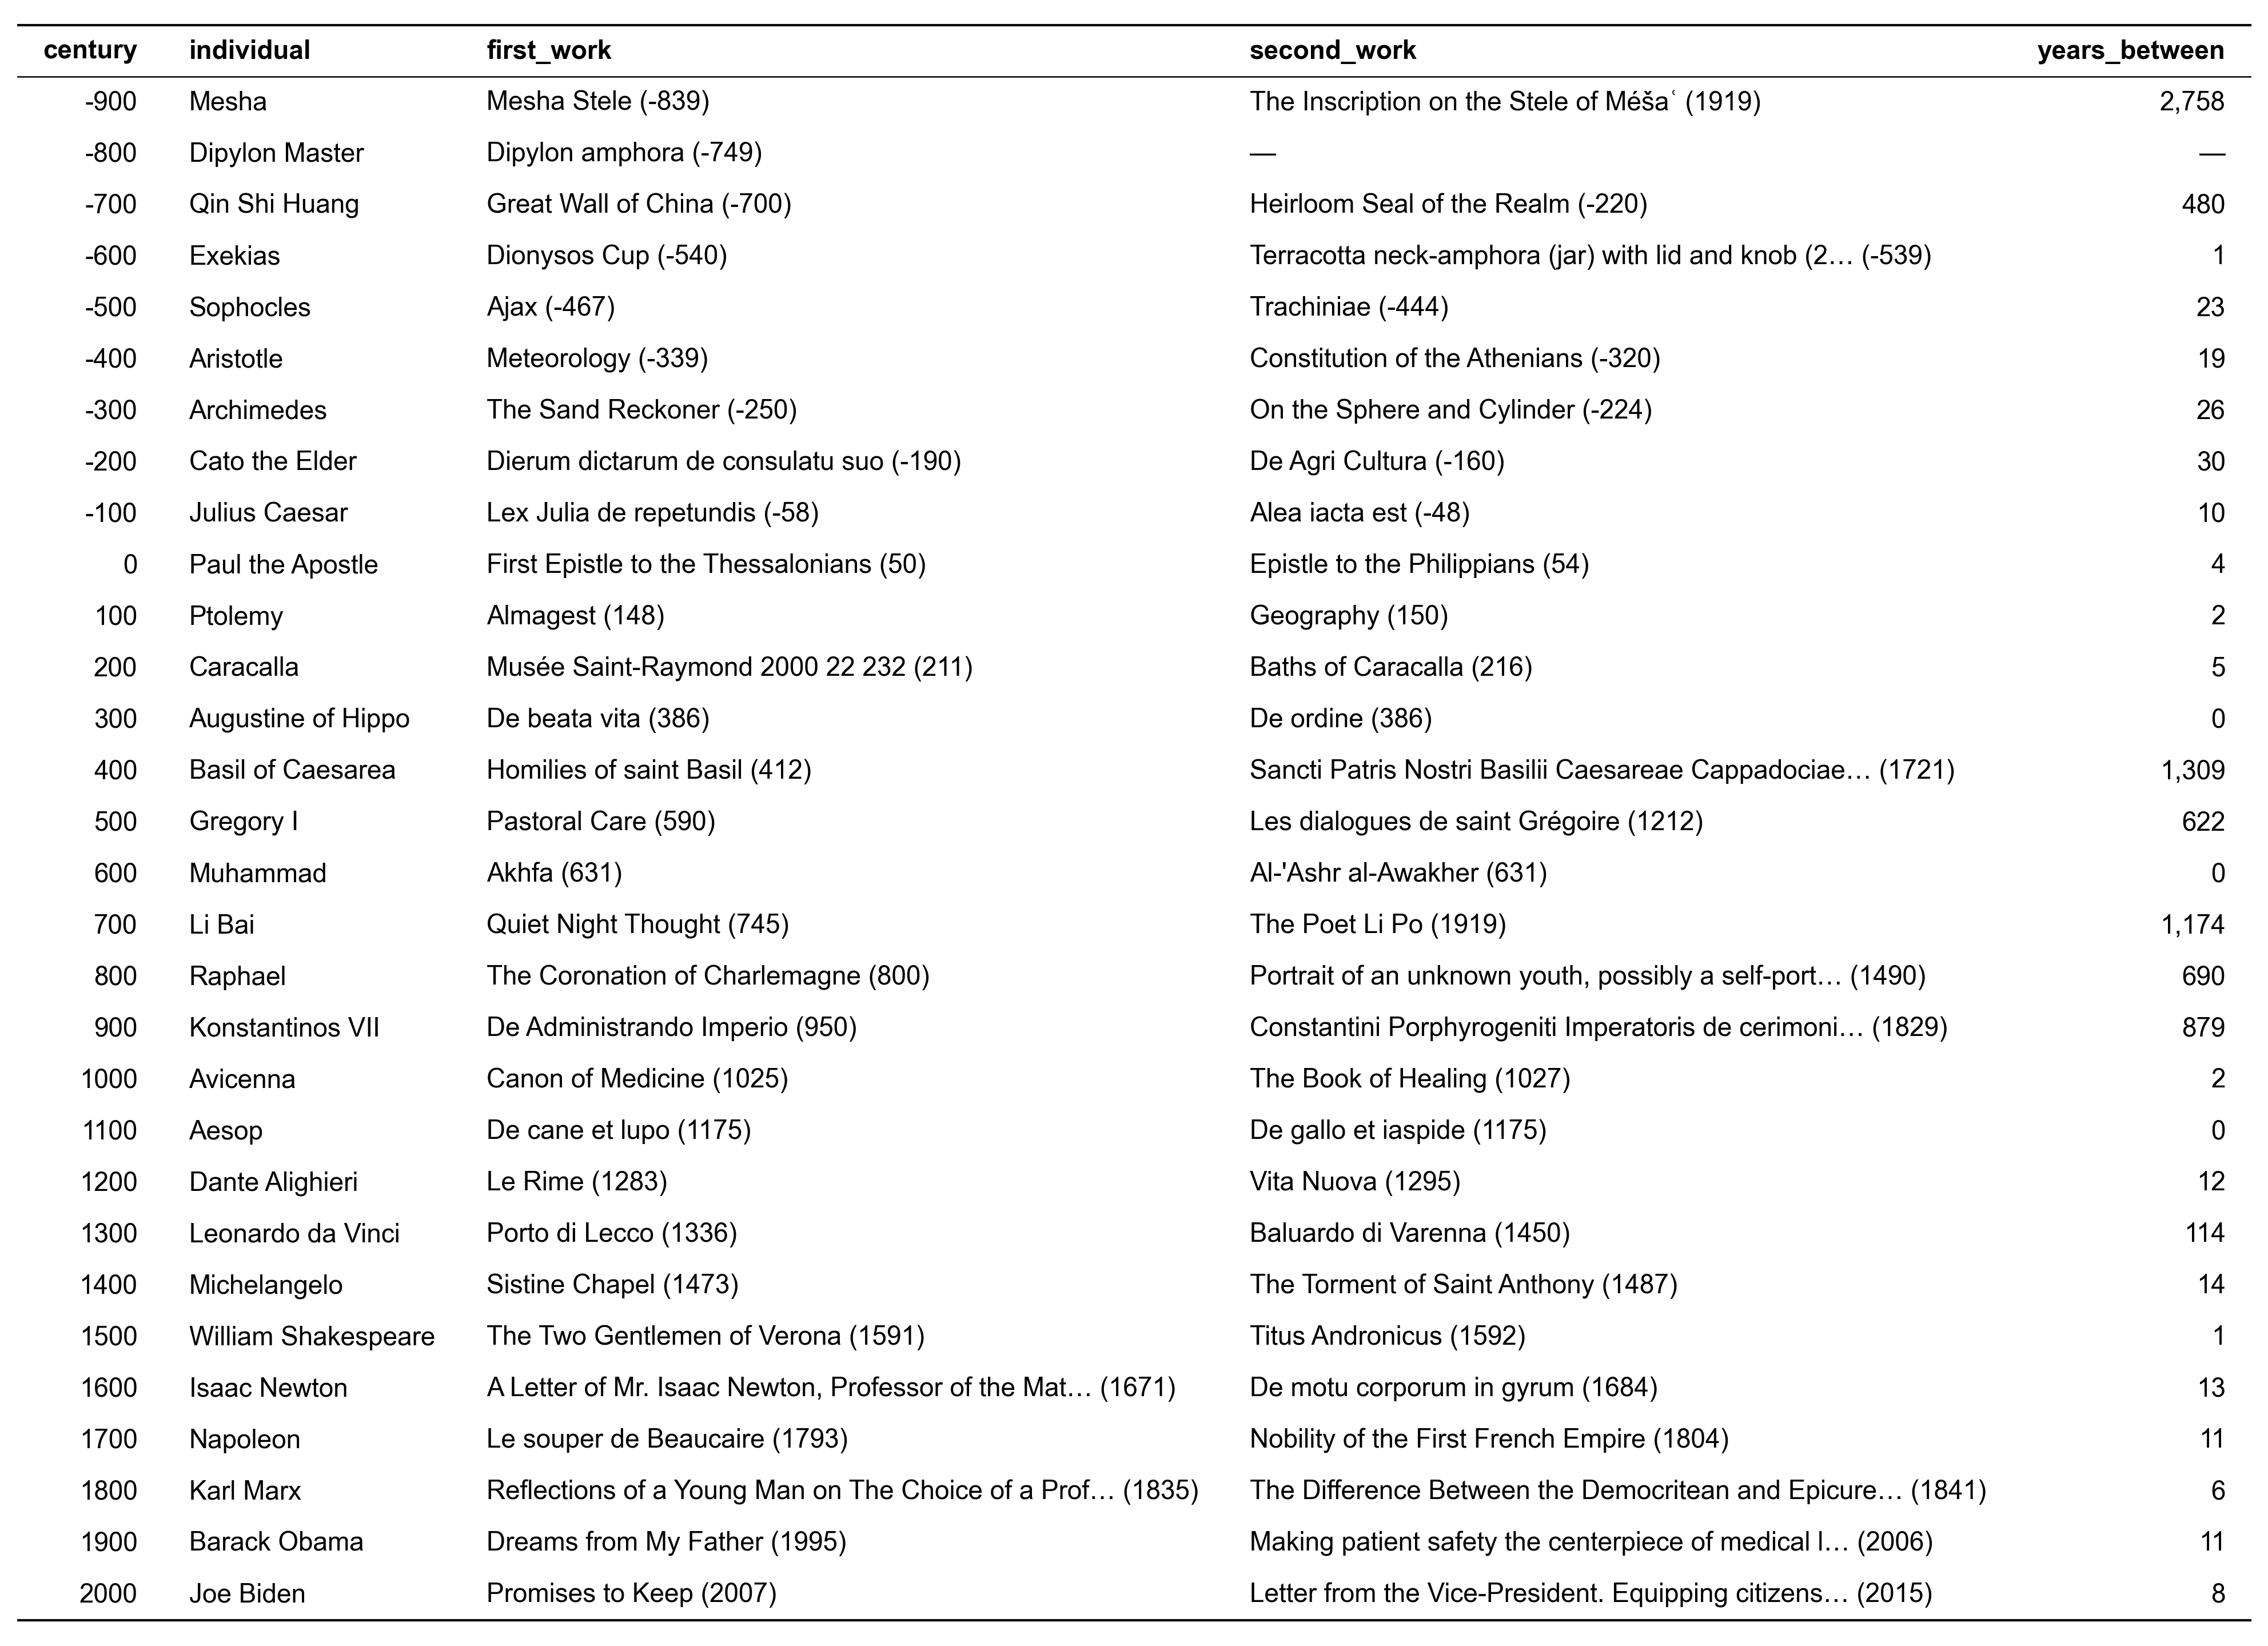

In [8]:
examples_input = two_precise.with_columns((pl.col('first_precise_year') // 100 * 100).alias('century_start')).filter(
    pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY)).select('qid', 'century_start')
connection.register('examples_input', examples_input.to_arrow())

examples = connection.execute('''
    WITH best AS (
        SELECT examples_input.century_start, examples_input.qid,
               coalesce(individual.entity.label_en, individual.entity.label_non_en) AS individual
        FROM examples_input
        JOIN individual ON individual.entity.qid = examples_input.qid
        QUALIFY row_number() OVER (PARTITION BY examples_input.century_start ORDER BY len(individual.sitelink) DESC, examples_input.qid) = 1
    ),
    dated AS (
        SELECT best.century_start, best.individual,
               coalesce(work.entity.label_en, work.entity.label_non_en) AS work,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM best
        JOIN individual_work ON individual_work.qid = best.qid
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    first_two AS (
        SELECT century_start, individual, year,
               CASE WHEN length(work) > 50 THEN left(work, 50) || '…' ELSE work END || ' (' || year || ')' AS work,
               row_number() OVER (PARTITION BY century_start ORDER BY year, work) AS position
        FROM dated
        WHERE precision IN ('day', 'month', 'year', 'decade') AND work IS NOT NULL
        QUALIFY position <= 2
    )
    SELECT century_start AS century, individual,
           max(work) FILTER (WHERE position = 1) AS first_work,
           max(work) FILTER (WHERE position = 2) AS second_work,
           max(year) FILTER (WHERE position = 2) - max(year) FILTER (WHERE position = 1) AS years_between
    FROM first_two
    GROUP BY ALL
    ORDER BY century_start
''').pl().with_columns(pl.col('century').cast(pl.String))
print(f'{examples.height} centuries, {two_precise_century.height} in the chart')
show_table(examples)

## 2. Individuals with "fl." in their description
The year is the first one written after "fl." ("fl. 1545-1565" → 1545; "fl. 1930s" → 1935; BC when "BC" or "BCE" follows). A description that gives only a century ("fl. 5th century", "fl. 15. century") has no year.

In [9]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(BCE?)\b)?'
fl_text = (
    floruit.filter(pl.col('description').str.contains(r'\bfl\.'))
    .with_columns(pl.col('description').str.extract_groups(fl_pattern).alias('match'))
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE).otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_year'))
    .with_columns(pl.when(pl.col('is_ordinal_century')).then(None).otherwise(pl.col('fl_year')).alias('fl_year'))
    .drop('match', 'is_decade', 'is_bc', 'is_ordinal_century', 'year')
)
print(f'{fl_text.height:,} individuals with "fl." in their description')
print(f"{fl_text.filter(pl.col('fl_year').is_not_null()).height:,} of them with a year after it")
fl_text.select('description', 'fl_year').sample(10, seed=1)

7,837 individuals with "fl." in their description
7,257 of them with a year after it


description,fl_year
str,i64
"""born:1685|died:1768-07-07|; Prault; Prault, Pierre, fl. 1711-1766?; Prault, Pier…",1711
"""(fl. 1822)""",1822
"""Italian publisher and bookseller (fl. 1656-1673)""",1656
"""(fl.1619-1648)""",1619
"""Italian printer (fl. 1681-1698)""",1681
"""ichthyologist fl. 1992""",1992
"""Italian printer (fl. 1817-1822)""",1817
"""Etcher and miniature painter, fl. 1764-71""",1764
"""planter and enslaver of Woodford County, Ky (fl. 1816-1864)""",1816


### By century of the year in the description

In [10]:
fl_century = by_century(fl_text, 'fl_year')
fl_century

582 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-600,2
-500,4
-400,5
-300,2
-200,2
-100,2
0,4
100,6
200,2


### Figure: individuals with "fl." in their description, by century

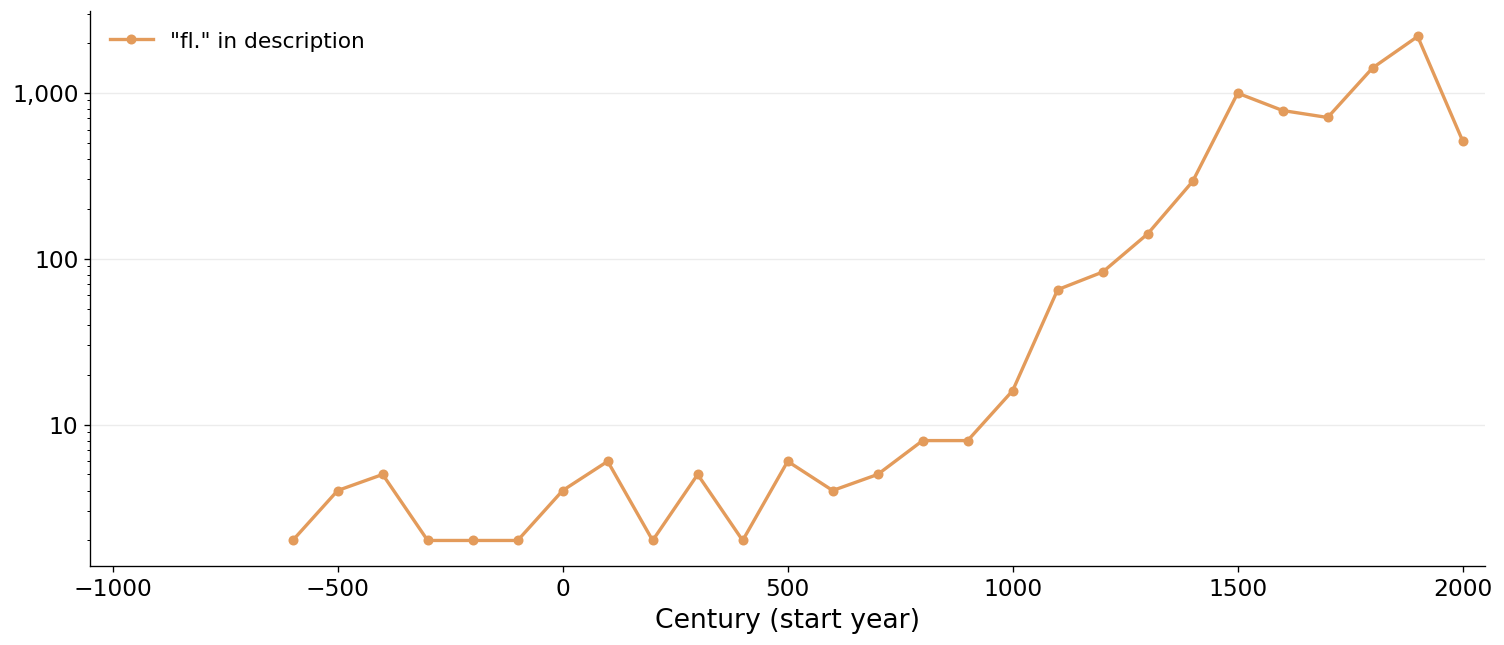

In [11]:
plot_centuries({'"fl." in description': fl_century})

## 3. Individuals with only one floruit date precise to the year or decade
One distinct year across their floruit dates. The last column counts those who also have no birth or death date.

In [12]:
one_floruit = floruit.filter(pl.col('precise_years').list.len() == 1).with_columns(
    pl.col('precise_years').list.first().alias('floruit_year'))
print(f'{one_floruit.height:,} individuals with exactly one year- or decade-precise floruit')
print(f"{one_floruit.filter(~pl.col('has_birth_or_death')).height:,} of them with no birth or death date")

55,835 individuals with exactly one year- or decade-precise floruit
36,029 of them with no birth or death date


### By century of the floruit

In [13]:
one_floruit_century = by_century(one_floruit, 'floruit_year').join(
    by_century(one_floruit.filter(~pl.col('has_birth_or_death')), 'floruit_year').rename({'individuals': 'without_birth_or_death'}),
    on='century_start', how='left',
).fill_null(0)
one_floruit_century

63 individuals outside -1000–2099 or without a year left out of the table
31 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals,without_birth_or_death
i64,u32,u32
-1000,1,1
-800,5,0
-700,2,2
-600,31,14
-500,58,34
-400,72,35
-300,51,32
-200,70,40
-100,73,42


### Figure: individuals with only one precise floruit, by century

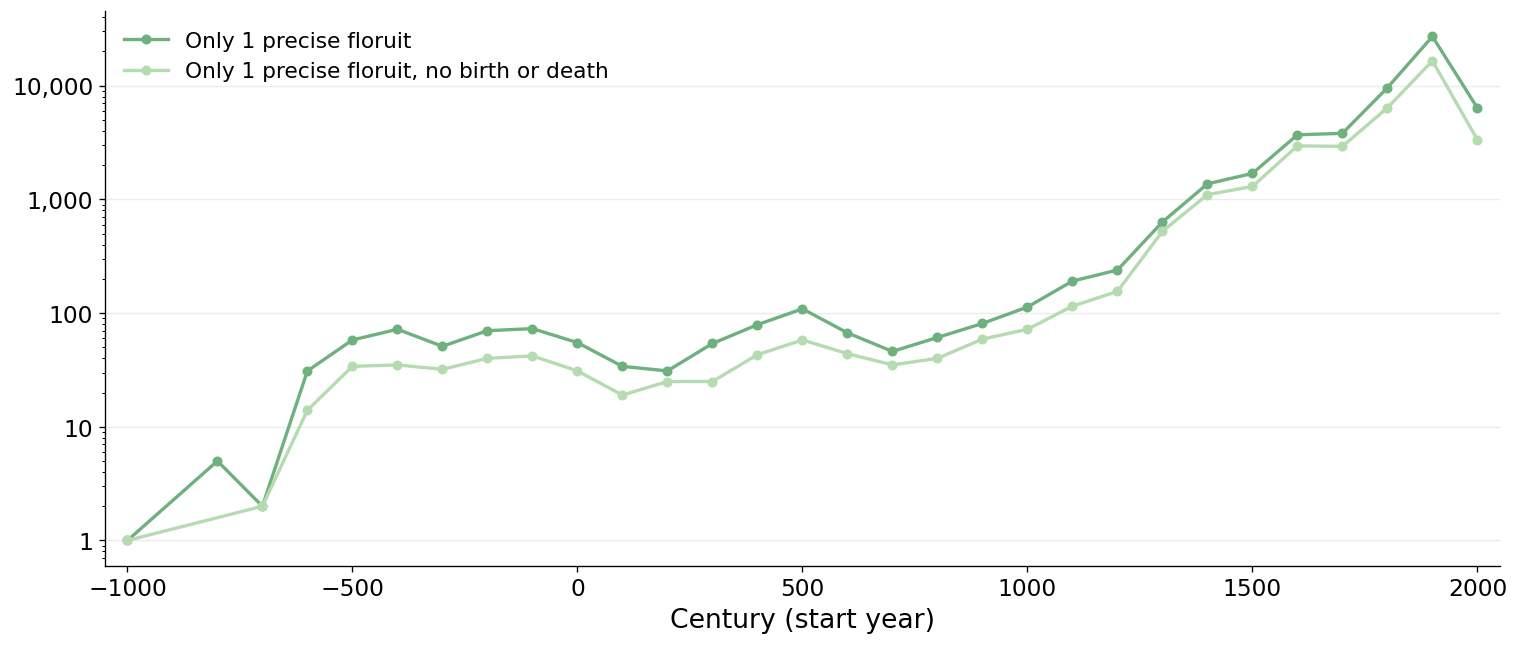

In [14]:
plot_centuries({
    'Only 1 precise floruit': one_floruit_century,
    'Only 1 precise floruit, no birth or death': one_floruit_century.select('century_start', pl.col('without_birth_or_death').alias('individuals')),
})

## 4. Individuals with only one work dated to the year or decade

In [15]:
one_work = works.filter(pl.col('precise_works') == 1)
print(f'{one_work.height:,} individuals with exactly one year- or decade-precise work')

984,063 individuals with exactly one year- or decade-precise work


### By century of that work

In [16]:
one_work_century = by_century(one_work, 'first_precise_year')
one_work_century

11 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-700,2
-600,33
-500,37
-400,45
-300,4
-200,8
-100,18
0,12


### Figure: individuals with only one precise work, by century

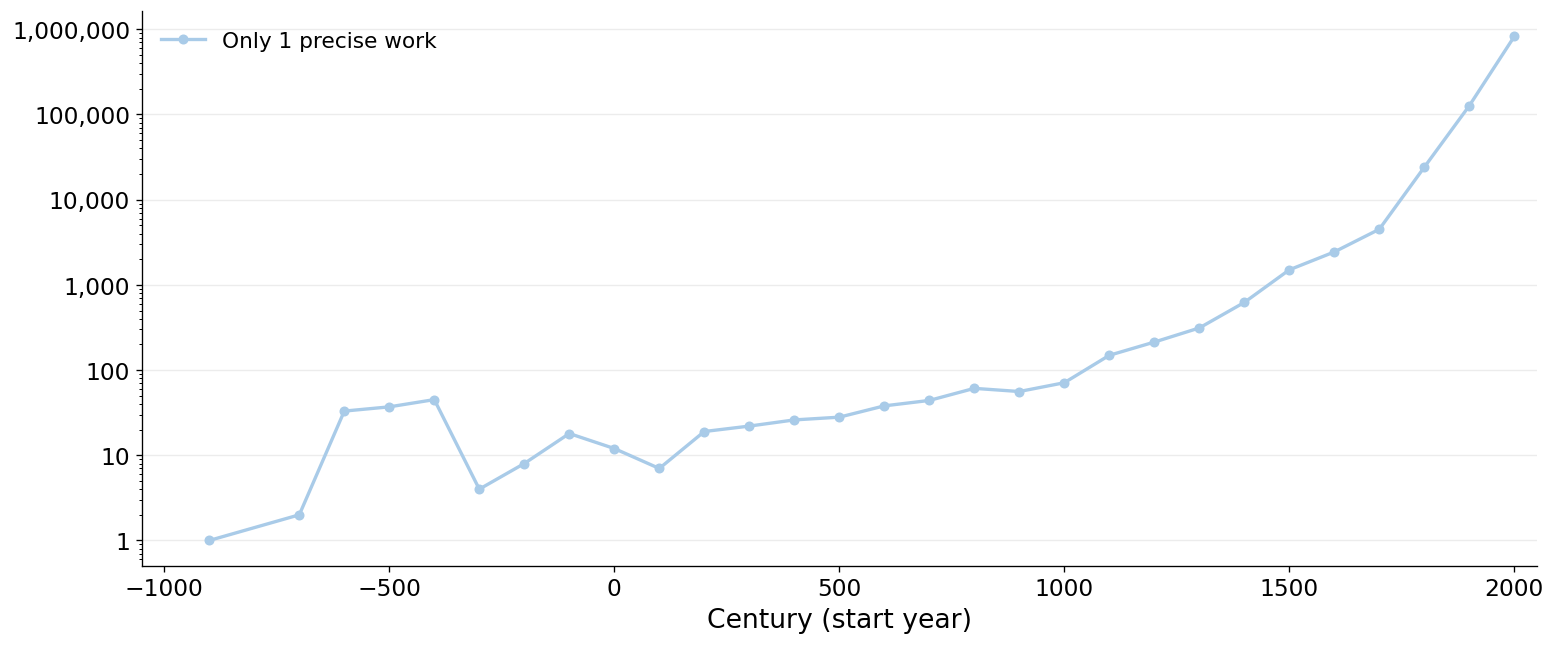

In [17]:
plot_centuries({'Only 1 precise work': one_work_century})

## Summary by century

Unique individuals in at least one of the four groups, each placed at the earliest of their years.

In [18]:
any_dates = (
    pl.concat([
        two_precise.select('qid', pl.col('first_precise_year').alias('year')),
        one_work.select('qid', pl.col('first_precise_year').alias('year')),
        fl_text.select('qid', pl.col('fl_year').alias('year')),
        one_floruit.select('qid', pl.col('floruit_year').alias('year')),
    ])
    .drop_nulls('year')
    .group_by('qid')
    .agg(pl.col('year').min())
)
assert any_dates['qid'].is_unique().all()
print(f'{any_dates.height:,} unique individuals in at least one of the four groups')
any_century = by_century(any_dates, 'year')
any_century

2,827,970 unique individuals in at least one of the four groups
80 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-1000,1
-900,2
-800,6
-700,6
-600,77
-500,131
-400,142
-300,62
-200,83


### Whole database by century
Every individual in the database, placed at their year in the groups above when they have one, else at birth + 30, or at death if they died younger. Year- or decade-precise birth and death dates come first; century or millennium ones are used only when there is nothing finer.

In [19]:
connection.register('any_dates', any_dates.to_arrow())
whole = connection.execute('''
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('century', 'millennium')]) AS coarse_birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('century', 'millennium')]) AS coarse_death_year
        FROM individual
    )
    SELECT floor(coalesce(any_dates.year, least(lifetime.birth_year + 30, lifetime.death_year), least(lifetime.coarse_birth_year + 30, lifetime.coarse_death_year)) / 100)::BIGINT * 100 AS century_start,
           count(*) AS individuals
    FROM lifetime
    LEFT JOIN any_dates ON any_dates.qid = lifetime.qid
    GROUP BY ALL
''').pl()
whole_century = whole.filter(pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY)).sort('century_start')
print(f"{whole['individuals'].sum():,} individuals in the database")
print(f"{whole.filter(pl.col('century_start').is_null())['individuals'].sum():,} without any birth, death, floruit or work date")
print(f"{whole.filter(pl.col('century_start').is_not_null() & ~pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY))['individuals'].sum():,} outside {FIRST_CENTURY}–{LAST_CENTURY + 99}")
whole_century

13,002,897 individuals in the database
3,044,601 without any birth, death, floruit or work date
1,695 outside -1000–2099


century_start,individuals
i64,i64
-1000,72
-900,124
-800,264
-700,364
-600,904
-500,1391
-400,1523
-300,1268
-200,1298


### Birth dates by century
Individuals with a birth date precise to the year or decade, and those whose birth date is only a century or millennium. Each is placed at birth + 30, like the whole database.

In [20]:
births = connection.execute('''
    WITH birth AS (
        SELECT list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS precise_year,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('century', 'millennium')]) AS coarse_year
        FROM individual
        WHERE len(birth_date) > 0
    )
    SELECT CASE WHEN precise_year IS NOT NULL THEN 'precise' ELSE 'coarse' END AS birth_precision,
           floor((coalesce(precise_year, coarse_year) + 30) / 100)::BIGINT * 100 AS century_start,
           count(*) AS individuals
    FROM birth
    WHERE coalesce(precise_year, coarse_year) IS NOT NULL
    GROUP BY ALL
''').pl()
print(births.group_by('birth_precision').agg(pl.col('individuals').sum()))
in_range = births.filter(pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY))
birth_precise_century = in_range.filter(pl.col('birth_precision') == 'precise').select('century_start', 'individuals').sort('century_start')
birth_coarse_century = in_range.filter(pl.col('birth_precision') == 'coarse').select('century_start', 'individuals').sort('century_start')
birth_precise_century.join(birth_coarse_century, on='century_start', how='full', coalesce=True, suffix='_coarse').sort('century_start')

shape: (2, 2)
┌─────────────────┬─────────────┐
│ birth_precision ┆ individuals │
│ ---             ┆ ---         │
│ str             ┆ i64         │
╞═════════════════╪═════════════╡
│ precise         ┆ 7349789     │
│ coarse          ┆ 138097      │
└─────────────────┴─────────────┘


century_start,individuals,individuals_coarse
i64,i64,i64
-1000,8,62
-900,11,94
-800,18,208
-700,43,243
-600,106,762
-500,192,1016
-400,285,1000
-300,320,781
-200,367,756


### Figure: all groups together

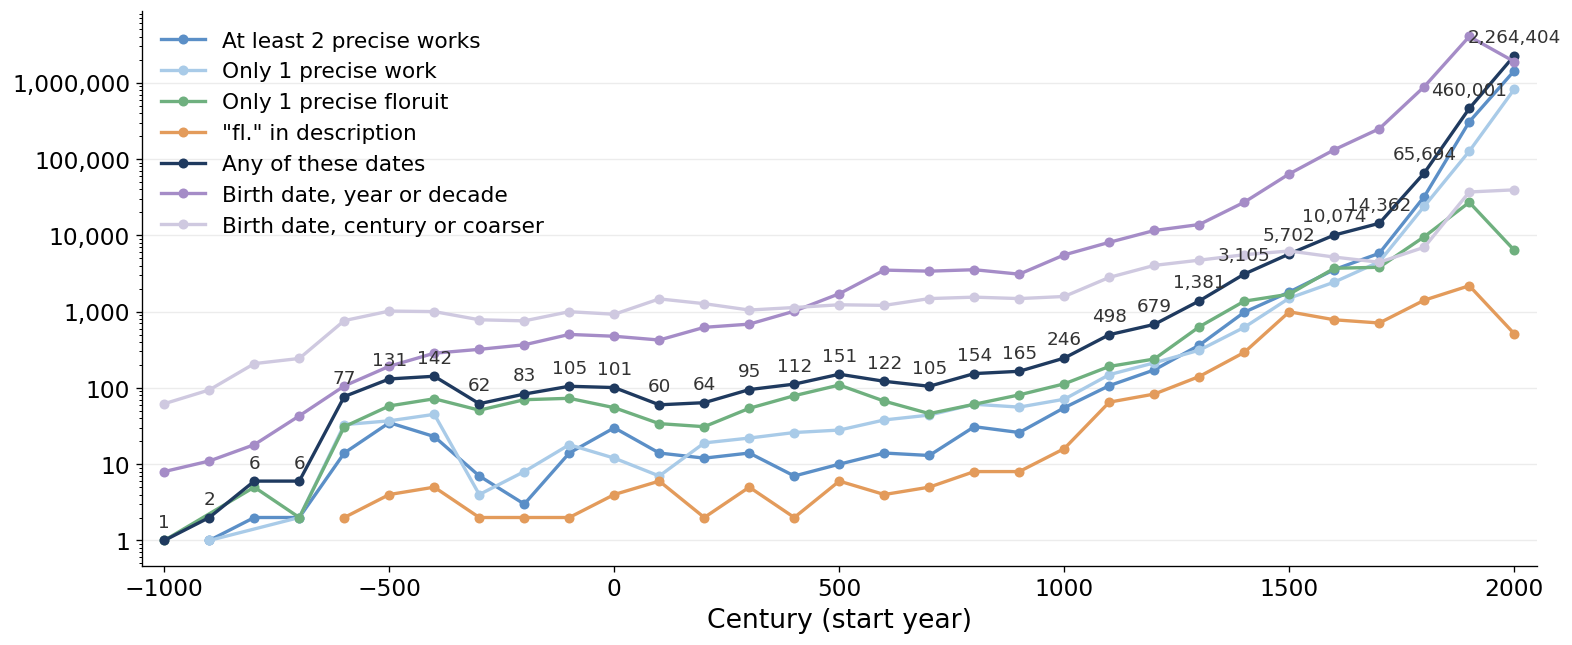

In [21]:
plot_centuries({
    'At least 2 precise works': two_precise_century,
    'Only 1 precise work': one_work_century,
    'Only 1 precise floruit': one_floruit_century,
    '"fl." in description': fl_century,
    'Any of these dates': any_century,
    'Birth date, year or decade': birth_precise_century,
    'Birth date, century or coarser': birth_coarse_century,
}, labelled=['Any of these dates'])

In [22]:
summary = (
    two_precise_century.rename({'individuals': 'two_or_more_precise_works'})
    .join(one_work_century.rename({'individuals': 'one_precise_work'}), on='century_start', how='full', coalesce=True)
    .join(fl_century.rename({'individuals': 'fl_in_description'}), on='century_start', how='full', coalesce=True)
    .join(one_floruit_century.select('century_start', 'individuals').rename({'individuals': 'one_precise_floruit'}), on='century_start', how='full', coalesce=True)
    .join(any_century.rename({'individuals': 'any_of_these_dates'}), on='century_start', how='full', coalesce=True)
    .join(birth_precise_century.rename({'individuals': 'birth_year_or_decade'}), on='century_start', how='full', coalesce=True)
    .join(birth_coarse_century.rename({'individuals': 'birth_century_or_coarser'}), on='century_start', how='full', coalesce=True)
    .join(whole_century.rename({'individuals': 'whole_dataset'}), on='century_start', how='full', coalesce=True)
    .fill_null(0)
    .with_columns((pl.col('any_of_these_dates') / pl.col('whole_dataset') * 100).round(1).alias('any_share_percent'))
    .sort('century_start')
)
summary

century_start,two_or_more_precise_works,one_precise_work,fl_in_description,one_precise_floruit,any_of_these_dates,birth_year_or_decade,birth_century_or_coarser,whole_dataset,any_share_percent
i64,u32,u32,u32,u32,u32,i64,i64,i64,f64
-1000,0,0,0,1,1,8,62,72,1.4
-900,1,1,0,0,2,11,94,124,1.6
-800,2,0,0,5,6,18,208,264,2.3
-700,2,2,0,2,6,43,243,364,1.6
-600,14,33,2,31,77,106,762,904,8.5
-500,35,37,4,58,131,192,1016,1391,9.4
-400,23,45,5,72,142,285,1000,1523,9.3
-300,7,4,2,51,62,320,781,1268,4.9
-200,3,8,2,70,83,367,756,1298,6.4


In [23]:
COLUMN_NAMES = {
    'century_start': 'Century',
    'two_or_more_precise_works': '≥ 2 precise works',
    'one_precise_work': '1 precise work',
    'fl_in_description': '"fl." in description',
    'one_precise_floruit': '1 precise floruit',
    'any_of_these_dates': 'Any of these',
    'birth_year_or_decade': 'Birth, year/decade',
    'birth_century_or_coarser': 'Birth, century+',
    'whole_dataset': 'Whole database',
}


def period_table(frame):
    counts = frame.drop('any_share_percent')
    total = counts.select(pl.lit('Total').alias('century_start'), pl.exclude('century_start').sum())
    table = pl.concat([counts.with_columns(pl.col('century_start').cast(pl.String)), total], how='vertical_relaxed')
    table = table.with_columns((pl.col('any_of_these_dates') / pl.col('whole_dataset') * 100).round(1).alias('Any / whole (%)'))
    show_table(table.rename(COLUMN_NAMES), decimals=1)

### Table: all centuries

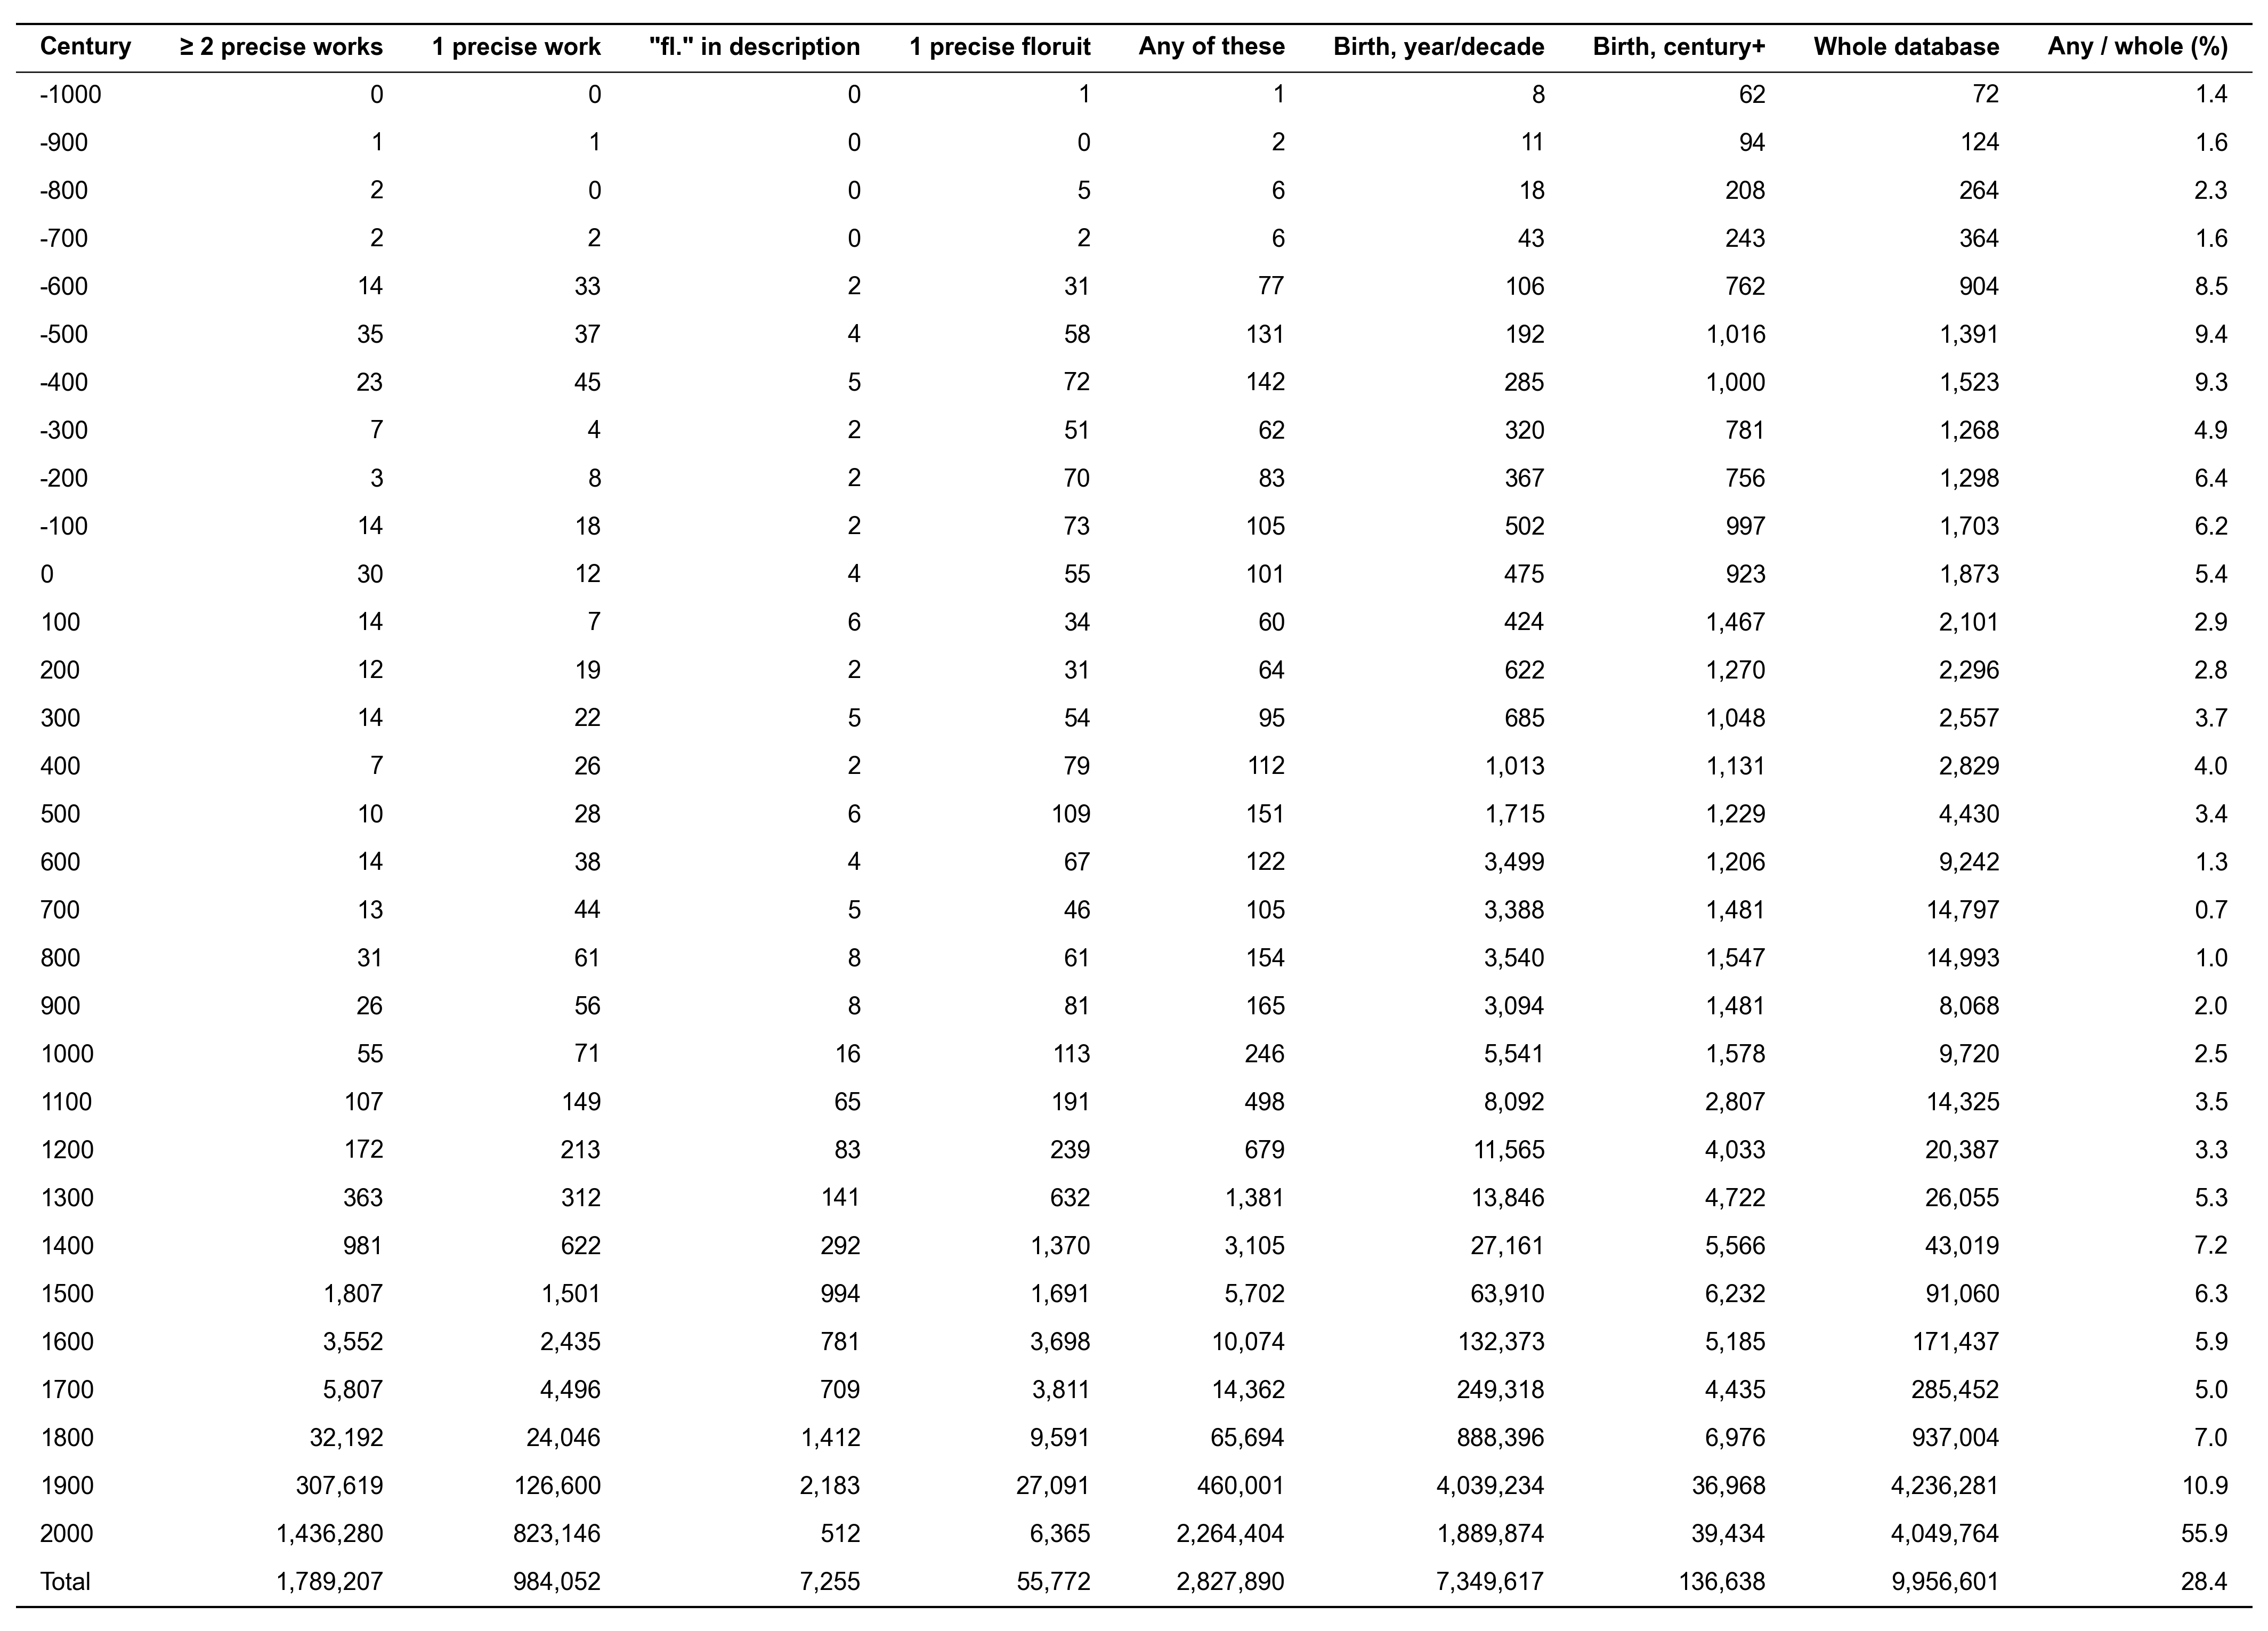

In [24]:
period_table(summary)

### Table: before 1500

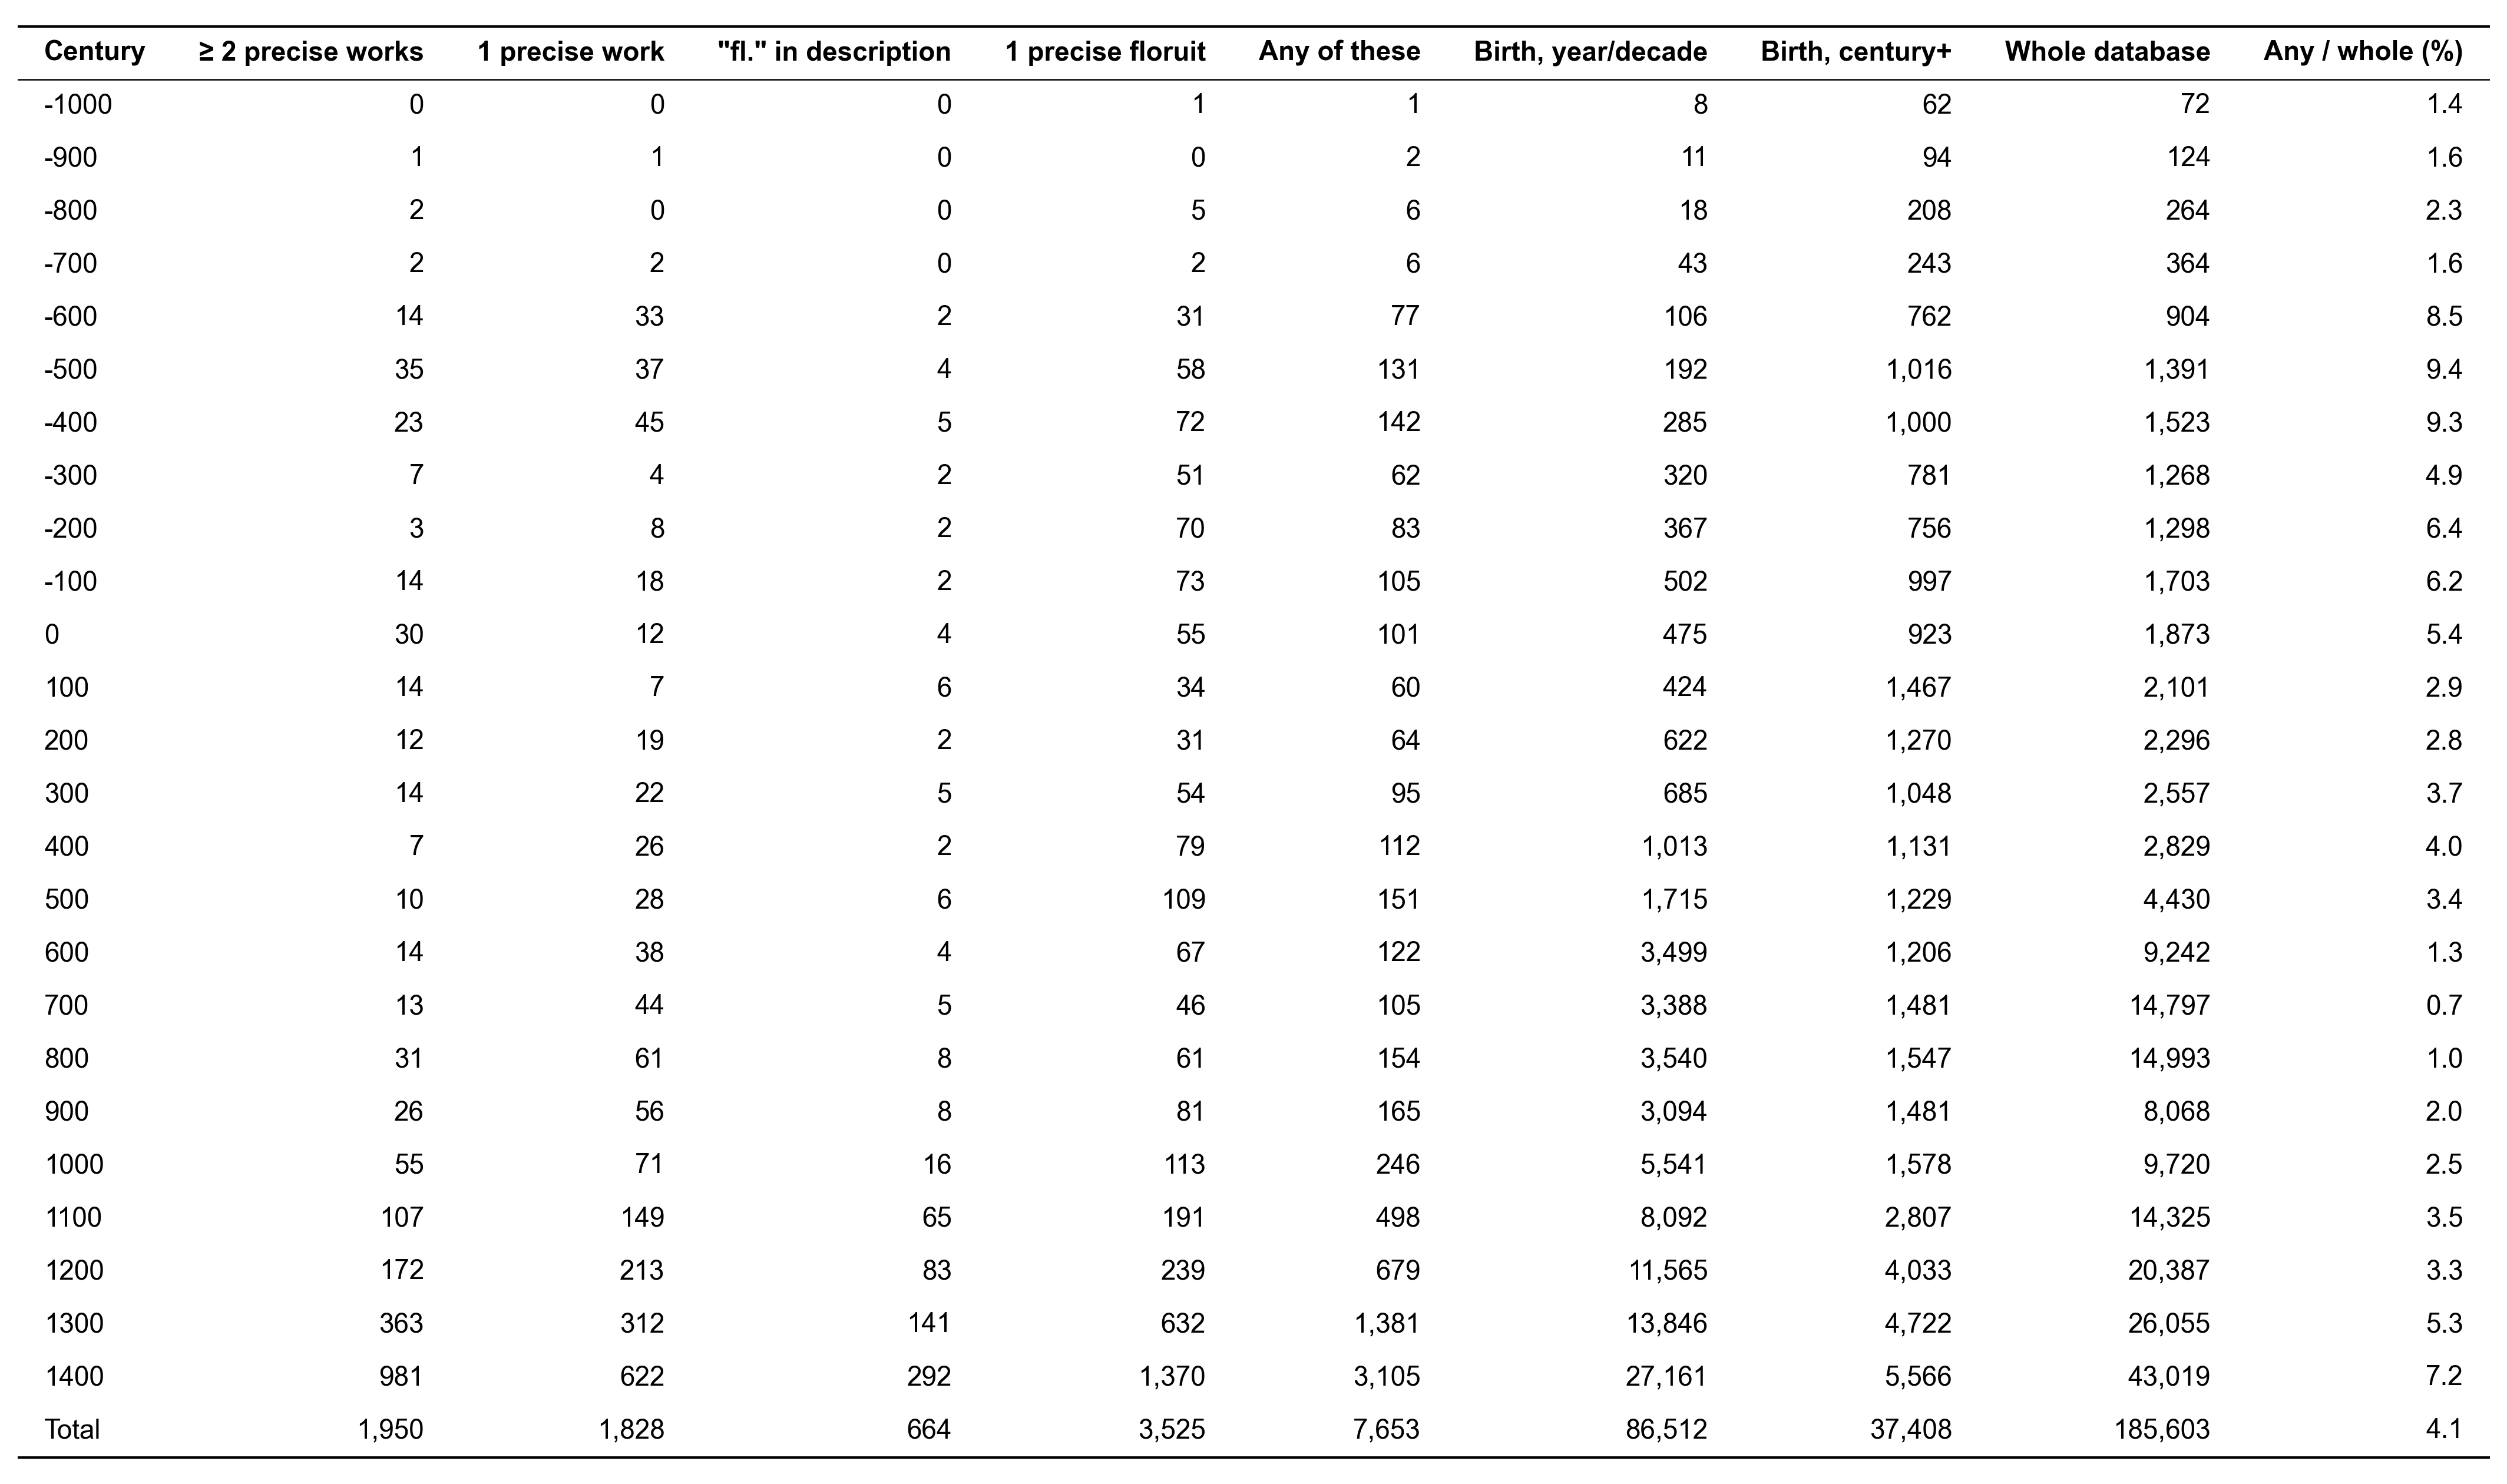

In [25]:
period_table(summary.filter(pl.col('century_start') < 1500))

### Table: 1500 and after

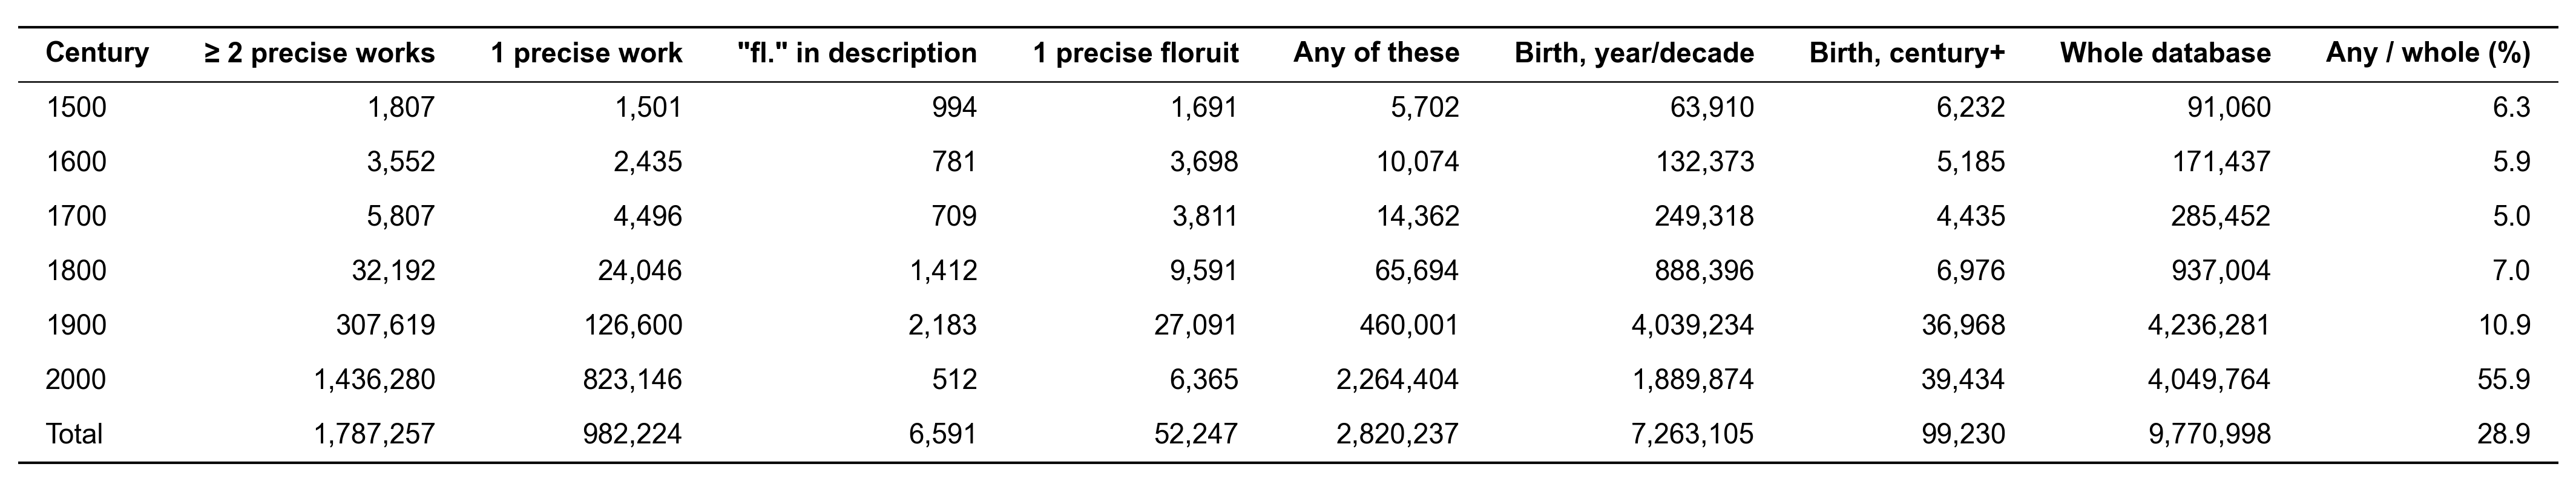

In [26]:
period_table(summary.filter(pl.col('century_start') >= 1500))